# Sales Performance Analysis | 2025

## Project Overview

This project analyzes a synthetic sales dataset containing 300 transactions from 2025 to identify sales trends, product performance, and regional revenue distribution.

Using Python, Pandas, and Matplotlib, I explored the dataset, calculated key performance metrics, created visualizations, and developed business recommendations based on the findings.

## Business Objectives

- Identify the highest revenue-generating product categories.
- Analyze monthly revenue trends.
- Compare sales performance across geographical regions.
- Identify the top-performing products by revenue and quantity sold.

## Tools & Technologies

- **Python:** Data analysis and calculations
- **Pandas:** Data manipulation and aggregation
- **Matplotlib:** Data visualization
- **Google Colab:** Development environment

## Dataset

The project uses 300 fictional sales transactions from 2025. The dataset was created for educational purposes and does not represent actual company sales.

In [48]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the sales dataset
df = pd.read_csv("sales.csv")

# Display first five rows
df.head()



,order_id,order_date,region,category,product,quantity,unit_price
0,ORD-0001,2025-01-13,East,Furniture,Office Chair,2,180
1,ORD-0002,2025-02-22,North,Electronics,Headphones,5,59
2,ORD-0003,2025-01-16,North,Office Supplies,Notebook,2,12
3,ORD-0004,2025-11-05,North,Electronics,Monitor,5,220
4,ORD-0005,2025-11-29,West,Electronics,Monitor,2,220


In [35]:
df.shape

(300, 7)

In [36]:
df.isnull().sum()

,0
order_id,0
order_date,0
region,0
category,0
product,0
quantity,0
unit_price,0


In [37]:

# Calculate revenue for each order
df["revenue"] = df["quantity"] * df["unit_price"]

# Calculate total revenue
total_revenue = df["revenue"].sum()

# Display the result
print(f"Total Sales Revenue: ${total_revenue:,.2f}")


Total Sales Revenue: $87,457.00


In [38]:

# Calculate total revenue by category
category_sales = df.groupby("category")["revenue"].sum()

# Sort categories from highest to lowest revenue
category_sales = category_sales.sort_values(ascending=False)

# Display results
print(category_sales)



category
Furniture          51250
Electronics        30573
Office Supplies     5634
Name: revenue, dtype: int64


**Business Insight #1: Revenue by Product Category**

Analysis of the sales dataset revealed that Furniture is the company's largest revenue-generating category, contributing $51,250 (58.6%) of total sales revenue. Electronics followed with $30,573 (35.0%), while Office Supplies accounted for $5,634 (6.4%).
These findings suggest that Furniture is a major revenue driver, while Office Supplies may warrant further investigation to understand its smaller revenue contribution.

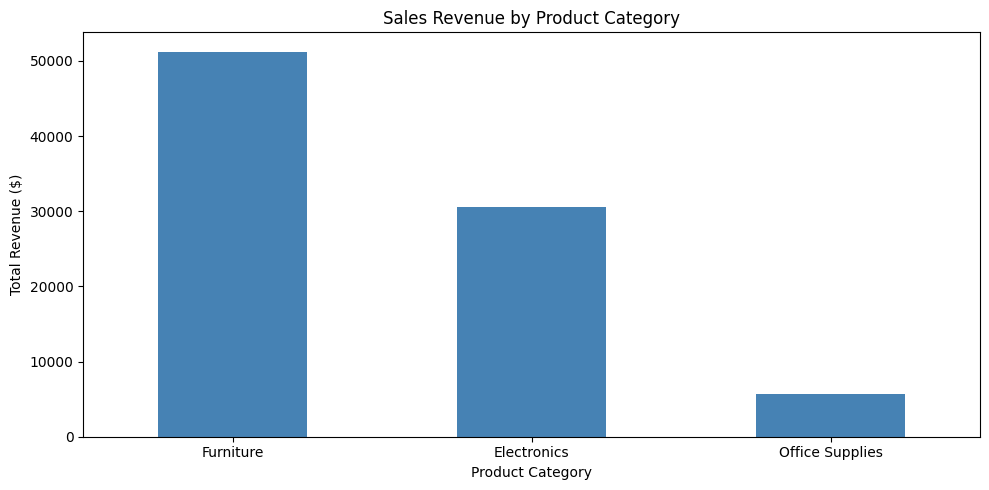

In [39]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

category_sales.plot(kind="bar", color="steelblue")

plt.title("Sales Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue ($)")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()


In [40]:

# Convert order_date into a datetime format
df["order_date"] = pd.to_datetime(df["order_date"])

# Check the result
print(df["order_date"].dtype)


datetime64[ns]


In [41]:

# Group sales revenue by month
monthly_sales = df.groupby(
    df["order_date"].dt.to_period("M")
)["revenue"].sum()

# Display monthly sales
print(monthly_sales)


order_date
2025-01     4651
2025-02    11460
2025-03     6118
2025-04     5803
2025-05     7850
2025-06     5366
2025-07     9696
2025-08     9555
2025-09     4112
2025-10     6700
2025-11     7962
2025-12     8184
Freq: M, Name: revenue, dtype: int64


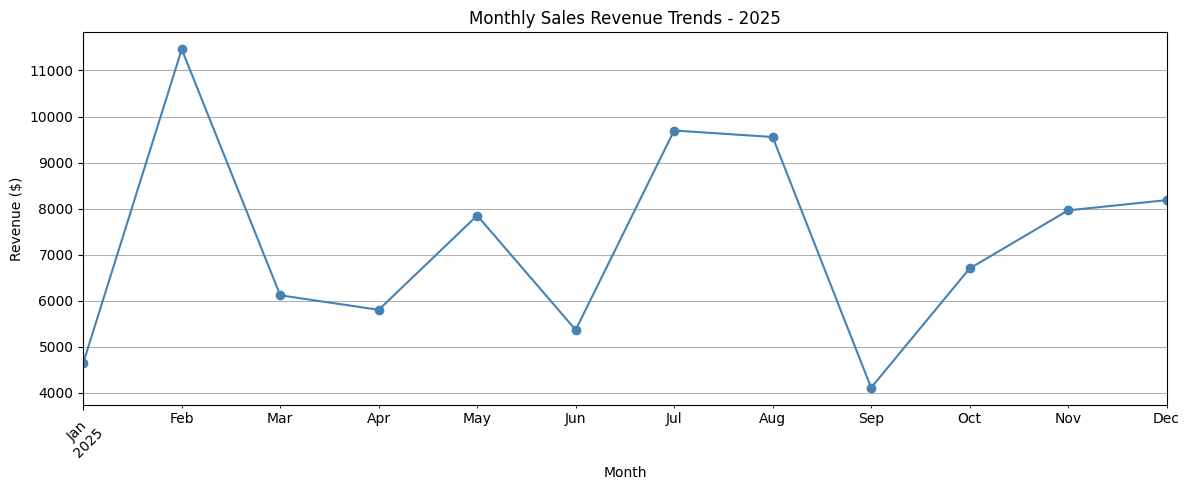

In [42]:

# Create a monthly revenue line chart
plt.figure(figsize=(12, 5))

monthly_sales.plot(
    kind="line",
    marker="o",
    color="steelblue"
)

plt.title("Monthly Sales Revenue Trends - 2025")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


**Business Insight #2: Monthly Sales Trends**

The analysis revealed that monthly sales revenue fluctuated throughout 2025.

February was the strongest-performing month, generating $11,460.

September experienced the lowest revenue,
generating $4,112.

Revenue increased consistently from October through December, suggesting positive sales momentum toward the end of the year.

**Recommendation:** Investigate the factors contributing to February's strong performance and September's decline. Additional information about promotions, customer demand, and seasonal purchasing behavior could help explain these trends.

In [43]:

# Calculate total revenue by region
region_sales = df.groupby("region")["revenue"].sum()

# Sort from highest to lowest
region_sales = region_sales.sort_values(ascending=False)

# Display the results
print(region_sales)


region
North    25915
West     23618
South    21775
East     16149
Name: revenue, dtype: int64


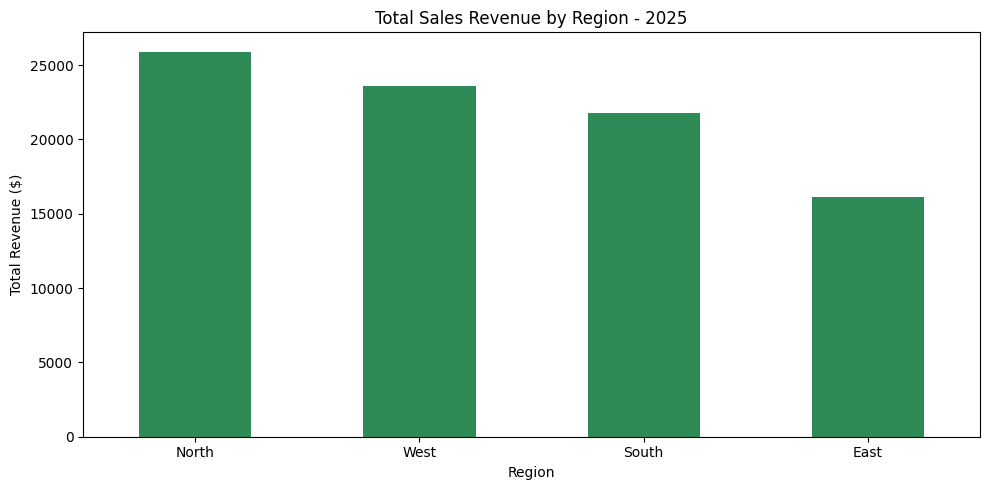

In [44]:

import matplotlib.pyplot as plt

# Create a bar chart
plt.figure(figsize=(10, 5))

# Plot revenue by region
region_sales.plot(
    kind="bar",
    color="seagreen"
)

# Add chart title and labels
plt.title("Total Sales Revenue by Region - 2025")
plt.xlabel("Region")
plt.ylabel("Total Revenue ($)")

# Improve readability
plt.xticks(rotation=0)
plt.tight_layout()

# Display chart
plt.show()


**Business Insight #3: Regional Sales Performance**

Regional sales analysis revealed that the North region generated the highest revenue in 2025, contributing $25,915 (29.6%) of total sales.

The West and South regions followed with $23,618 and $21,775, respectively.

The East region generated the lowest revenue at $16,149, accounting for 18.5% of total sales.

**Recommendation:** Investigate the differences in regional sales performance, including order volume, average order value, and customer demand, to identify opportunities for growth.

In [45]:

# Calculate total revenue by product
product_sales = df.groupby("product")["revenue"].sum()

# Sort products from highest to lowest
product_sales = product_sales.sort_values(ascending=False)

# Display results
print(product_sales)


product
Desk              28210
Office Chair      18900
Monitor           17160
Keyboard           7395
Headphones         6018
Lamp               4140
Desk Organizer     3192
Notebook           1380
Pens               1062
Name: revenue, dtype: int64


In [46]:

# Calculate total quantity sold by product
product_quantity = df.groupby("product")["quantity"].sum()

# Sort from highest to lowest
product_quantity = product_quantity.sort_values(ascending=False)

# Display the results
print(product_quantity)


product
Pens              118
Notebook          115
Desk Organizer    114
Office Chair      105
Headphones        102
Lamp               92
Desk               91
Keyboard           87
Monitor            78
Name: quantity, dtype: int64


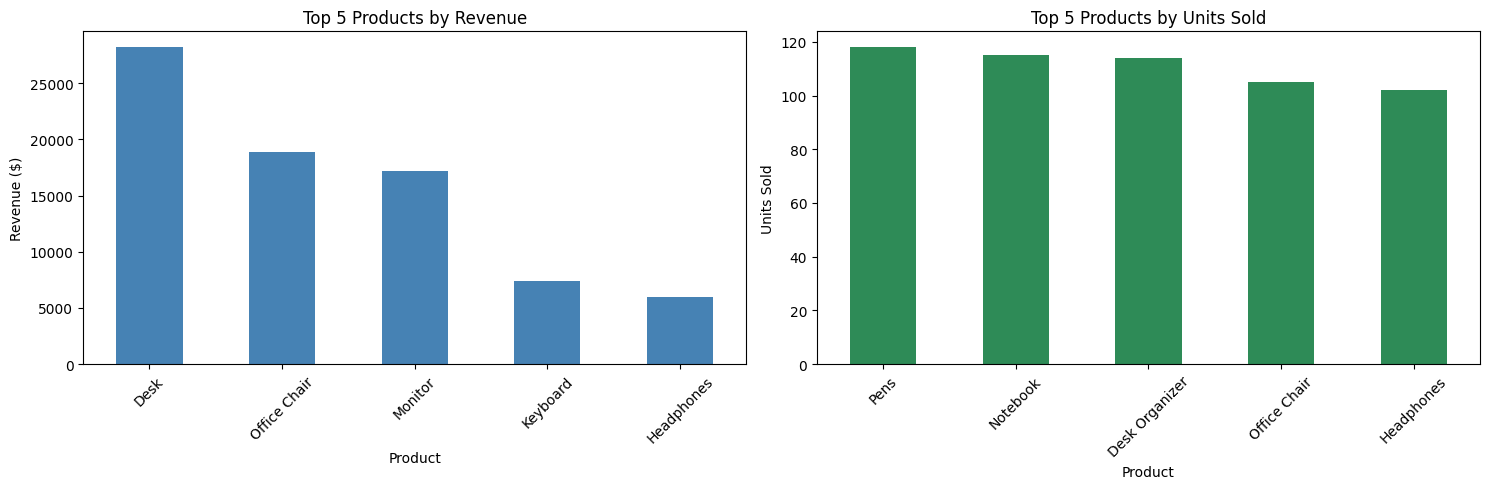

In [47]:

# Create two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Chart 1: Top 5 products by revenue
product_sales.head(5).plot(
    kind="bar",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Top 5 Products by Revenue")
axes[0].set_xlabel("Product")
axes[0].set_ylabel("Revenue ($)")
axes[0].tick_params(axis="x", rotation=45)

# Chart 2: Top 5 products by quantity
product_quantity.head(5).plot(
    kind="bar",
    ax=axes[1],
    color="seagreen"
)

axes[1].set_title("Top 5 Products by Units Sold")
axes[1].set_xlabel("Product")
axes[1].set_ylabel("Units Sold")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


**Business Insight #4: Product Performance**

The product performance analysis revealed that desks generated the highest revenue at $28,210, despite selling only 91 units.

In contrast, pens recorded the highest sales volume at 118 units but generated only $1,062 in revenue.

This demonstrates that high sales volume does not necessarily translate into high revenue. Higher-priced products can generate significantly more revenue while selling fewer units.

**Recommendation:** Evaluate both revenue and sales volume when making inventory and product strategy decisions. Further analysis of profitability and demand could help identify which products should receive additional investment.

## Executive Summary

The analysis of 2025 sales data revealed several key findings:

- **Total Revenue:** $87,457
- **Highest Revenue Category:** Furniture ($51,250)
- **Strongest Sales Month:** February ($11,460)
- **Highest Revenue Region:** North ($25,915)
- **Highest Revenue Product:** Desk ($28,210)
- **Highest Sales Volume Product:** Pens (118 units)

### Business Recommendations

1. Investigate opportunities to sustain revenue from furniture products, the company's largest revenue-generating category.
2. Analyze factors that may explain the differences in monthly revenue, particularly February's peak and September's decline.
3. Evaluate regional order volume and average order value to better understand why the East region generates less revenue.
4. Consider both revenue and unit sales when evaluating individual product performance.

### Conclusion

This project demonstrates how Python-based data analysis can turn raw sales transactions into meaningful business insights that support decision-making.